In [3]:
import numpy as np
import pandas as pd
import torch
import h5py
import joblib
import os, sys
import subprocess
import matplotlib.pyplot as plt
import math, json

In [4]:
sys.path.insert(0, "/mnt/efsUCE/umap_pytorch")  #git+https://github.com/ucscBrainExplorer/umap_pytorch.git
import umap_pytorch
print(umap_pytorch.__file__)

/mnt/efsUCE/umap_pytorch/umap_pytorch/__init__.py


In [7]:
from s3dir import workdir, push

results_dir = "/mnt/efsUCE/analysis/platform_viz_alignment/HNOCA/v2v3dropseq_w0only/"

embedding_h5_file = "pca_corrected.h5"
embedding_h5_file_key = "pca"
knn_outfile = "knn_15.npz"
k = 10
metadata_file = "obs.tsv"

existing_model_iteration = 0
epochs = 10

# A local folder is used as is; an S3 prefix (s3://latentbrain/...) is synced into a local
# cache, fetching only the files training reads
results_dir = workdir(results_dir, files=[embedding_h5_file, knn_outfile, metadata_file,
                                          f"pytorch_e{existing_model_iteration}.pkl"])

In [8]:
metadata = pd.read_csv(os.path.join(results_dir, metadata_file), sep ='\t')
labels = metadata["harmonized_cell_label"].values

## Load Embedding back into memory

In [9]:
# Load the embedding data
# Open the HDF5 file
with h5py.File(os.path.join(results_dir, embedding_h5_file), "r") as f:
    X_data = f[embedding_h5_file_key][:]

# Convert to PyTorch tensor so to use gpu
data_tensor = torch.from_numpy(X_data)
data_tensor, data_tensor.shape

(tensor([[-0.1959,  0.0865, -0.2319,  ...,  0.0868, -0.0108,  0.0599],
         [-0.2053,  0.0445, -0.2593,  ...,  0.0717,  0.0010,  0.1374],
         [-0.1248,  0.1750, -0.2725,  ...,  0.0402, -0.0340,  0.0993],
         ...,
         [ 0.0797, -0.0768,  0.0926,  ..., -0.0098,  0.0213,  0.0498],
         [ 0.1938,  0.0691,  0.0463,  ...,  0.0969, -0.0746, -0.0027],
         [ 0.0530, -0.0150,  0.1449,  ...,  0.2259,  0.0597,  0.0406]]),
 torch.Size([1686006, 50]))

## Load Knn Back

In [10]:
# load knn back
data = np.load(os.path.join(results_dir, knn_outfile))
knn_indices = data["indices"]
knn_distances = data["distances"]

In [11]:
knn_distances = np.sqrt(knn_distances)

## PUMAP 
using umap_pytorch https://github.com/ucscBrainExplorer/umap_pytorch.git

## set up training on all cells

In [12]:
knn_indices = knn_indices[:,:k]
knn_dists = knn_distances[:,:k]

### Load model back or start with a new model

In [13]:
if existing_model_iteration > 0:
    from umap_pytorch import load_pumap
    path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
    pumap = load_pumap(path)
    pumap.epochs = epochs
    print ("Start with existing model", f'pytorch_e{existing_model_iteration}.pkl')
else:
    import torch.nn.functional as F
    pumap = umap_pytorch.PUMAP(
        encoder=None,           # nn.Module, None for default
        decoder=None,           # nn.Module, True for default, None for encoder only
        n_neighbors=10,
        min_dist= 0.1,
        metric="euclidean",
        n_components=2,
        beta=1.0,               # How much to weigh reconstruction loss for decoder
        reconstruction_loss=F.binary_cross_entropy_with_logits, # pass in custom reconstruction loss functions
        random_state=None,
        lr=1e-3,
        epochs=epochs, #5,
        batch_size= 512, #256, #64, # gpu memory related
        num_workers=0, #10,
        num_gpus=1,
        match_nonparametric_umap=False, # Train network to match embeddings from non parametric umap,
    )
    print ("Start with a new model")

Start with a new model


### Train

In [14]:
existing_model_iteration, pumap.epochs

(0, 10)

In [15]:
np.product = np.prod  # alias to fix compatibility
pumap.fit(data_tensor, knn_indices, knn_dists, y=labels)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ec2-user/.local/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default


Fitting parametric Umap
There are knn provided by the user
Start fuzzy_simplicial_set ...
End fuzzy_simplicial_set
Adding supervision...
Supervision applied.
Training start
Start UMAPDataset initiation ...
batch_size: 512
End UMAPDataset. 3242659328 1686006


/mnt/efsUCE/umap_pytorch/umap_pytorch/data.py:37: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, device="cuda")
You are using a CUDA device ('NVIDIA A10G') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type            | Params | Mode 
----------------------------------------------------
0 | encoder | default_encoder | 91.0 K | train
----------------------------------------------------
91.0 K    Trainable params
0         Non-trainable params
91.0 K    Total params
0.364     Total estimated mode

dataloader len: 3292


/home/ec2-user/.local/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=10` reached.


### Saving model

In [16]:
existing_model_iteration = existing_model_iteration+ pumap.epochs
existing_model_iteration

10

In [17]:
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
pumap.save(model_path)

Pickled PUMAP object at /mnt/efsUCE/analysis/platform_viz_alignment/HNOCA/v2v3dropseq_w0only/pytorch_e10.pkl


### Quick viz X_umap_pytorch

In [18]:
# load model
from umap_pytorch import load_pumap
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
#model_path = os.path.join(results_dir, f'pytorch_e10.pkl')
pumap = load_pumap(model_path)
print("Loaded model", f'pytorch_e{existing_model_iteration}.pkl')

Loading PUMAP object from pickled file.
Loaded model pytorch_e10.pkl


#### random 200K

In [19]:
view_size = 200_000
if X_data.shape[0] < view_size:
    subset_indices = range (0, X_data.shape[0])
else:
    np.random.seed(42)  # set seed for reproducibility
    subset_indices = np.random.choice(X_data.shape[0], size= view_size, replace=False)

In [20]:
X_umap_pytorch = pumap.transform(data_tensor[subset_indices])

Reducing array of shape torch.Size([200000, 50]) to (200000, 2)


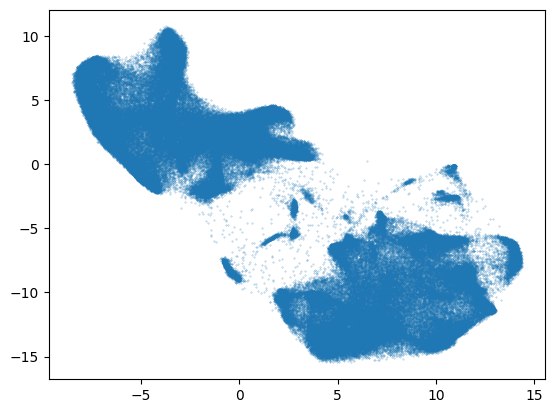

In [21]:
# current
plt.scatter(X_umap_pytorch[:,0], X_umap_pytorch[:,1], alpha =0.5, s=0.1)
plt.show()

## optional quick viz with metadata

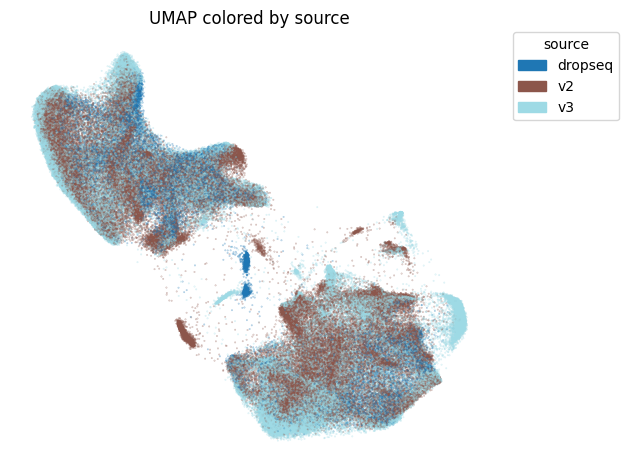

In [22]:
import matplotlib.pyplot as plt                                                                                                                                                                           
import matplotlib.patches as mpatches  
from matplotlib.colors import Normalize                                                                                                                                                                   
                                                                                                                                                                                                        
metadata_feature = "source"                                                                                                                                                        
                                                        
colors = metadata[metadata_feature].iloc[subset_indices]        

# only top category are plotted
top_cats = colors.value_counts().nlargest(20).index                                                                                                                                                       
colors = colors.where(colors.isin(top_cats), other="other")

categories = colors.astype('category')                    
category_codes = categories.cat.codes
unique_cats = categories.cat.categories                                                                                                                                                                   

cmap = plt.get_cmap('tab20')                                                                                                                                                                               
norm = Normalize(vmin=0, vmax=len(unique_cats) - 1)       

scatter = plt.scatter(X_umap_pytorch[:, 0], X_umap_pytorch[:, 1],                                                                                                                                         
                    c=category_codes, alpha=0.5, s=0.1, cmap=cmap, norm=norm)
                                                                                                                                                                                                        
patches = [mpatches.Patch(color=cmap(norm(i)), label=cat)                                                                                                                                                 
         for i, cat in enumerate(unique_cats)]
plt.legend(handles=patches, markerscale=5, title=metadata_feature,                                                                                                                                        
         bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.axis('off')                                                                                                                                                                                           
plt.title(f"UMAP colored by {metadata_feature}")
plt.tight_layout()                                                                                                                                                                                        
plt.show() 

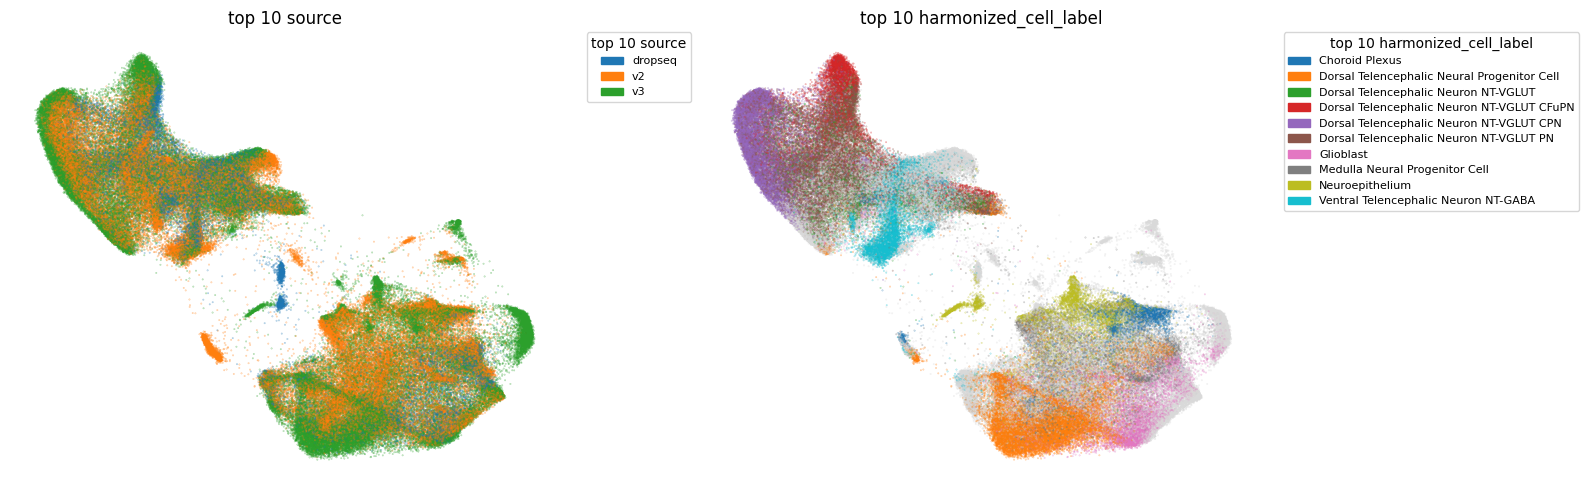

In [26]:
import matplotlib.pyplot as plt                                                                                                                                                                           
import matplotlib.patches as mpatches  
                                                                                                                                                                                                        
features = [ "source", "harmonized_cell_label"]                                                                                                                                                   
top_n = 10                                                                                                                                                                                                
                                                    
fig, axes = plt.subplots(int(len(features)/2), 2, figsize=(16, 5* int(len(features)/2)))                                                                                                                                                          
axes = axes.flatten()                                                                                                                                                           

for ax, metadata_feature in zip(axes, features):                                                                                                                                                          
  colors = metadata[metadata_feature].iloc[subset_indices]
  top_cats = colors.value_counts().nlargest(top_n).index
  labels = colors.where(colors.isin(top_cats), other="other")                                                                                                                                           
  unique_cats = [c for c in labels.astype('category').cat.categories if c != "other"]
                                                                                                                                                                                                        
  cmap = plt.get_cmap('tab10')                          
  color_map = {cat: cmap(i / top_n) for i, cat in enumerate(unique_cats)}                                                                                                                               
  color_map["other"] = (0.85, 0.85, 0.85, 0.3)          
  point_colors = labels.map(color_map)                                                                                                                                                                  

  ax.scatter(X_umap_pytorch[:, 0], X_umap_pytorch[:, 1],                                                                                                                                                
             c=point_colors, alpha=0.5, s=0.1)          
                                                                                                                                                                                                        
  patches = [mpatches.Patch(color=color_map[cat], label=cat) for cat in unique_cats]
  ax.legend(handles=patches, markerscale=5, title=f"top {top_n} {metadata_feature}",                                                                                                                    
            bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0, fontsize=8)                                                                                                                    
  ax.axis('off')
  ax.set_title(f"top {top_n} {metadata_feature}")                                                                                                                                                       
                                                                                                                                                                                                        
plt.tight_layout()
plt.show()   

### Save UMAP

In [27]:
n_samples = data_tensor.shape[0]
embedding_dim = 2  # since n_components=2
X_umap_pytorch = np.zeros((n_samples, embedding_dim), dtype=np.float32)

# --- Batch transform ---
print("Starting batch transformation ...", flush=True)
batch_size = 1_000_000
for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)
    batch = data_tensor[start:end]
    emb = pumap.transform(batch)
    X_umap_pytorch[start:end] = emb
    print(f"Processed {end}/{n_samples}", flush=True)

Starting batch transformation ...
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 1000000/1686006
Reducing array of shape torch.Size([686006, 50]) to (686006, 2)
Processed 1686006/1686006


In [28]:
config = {}
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
config["pumap_model_file"] = model_path
config["pca_model_file"]= os.path.join(results_dir,"ipca_model.pkl") # hard-coded for ipca transformation
config["knn_k"] = 30
config["knn_nprobe"] = 20
config["pca_n_components"] =50

# --- Axis adjustment ---
UMAP1_size = np.ptp(X_umap_pytorch[:, 0])
UMAP2_size = np.ptp(X_umap_pytorch[:, 1])
if UMAP1_size < UMAP2_size:
    print("Swapping axes (too tall UMAP)...", flush=True)
    X_umap_pytorch[:, [0, 1]] = X_umap_pytorch[:, [1, 0]]
    config["swap_xy_matrix"] =  [
        [0, 1],
        [1, 0]
    ]
else:
    config["swap_xy_matrix"] =  [
        [1, 0],
        [0, 1]
    ]
config["PUMAP_k"]=k
config

Swapping axes (too tall UMAP)...


{'pumap_model_file': '/mnt/efsUCE/analysis/platform_viz_alignment/HNOCA/v2v3dropseq_w0only/pytorch_e10.pkl',
 'pca_model_file': '/mnt/efsUCE/analysis/platform_viz_alignment/HNOCA/v2v3dropseq_w0only/ipca_model.pkl',
 'knn_k': 30,
 'knn_nprobe': 20,
 'pca_n_components': 50,
 'swap_xy_matrix': [[0, 1], [1, 0]],
 'PUMAP_k': 10}

In [29]:
# --- Saveing transformation config ----
config_path = os.path.join(results_dir, f"transform_e{existing_model_iteration}.json")
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

In [30]:
# --- Save umap ----
umap_file = f"umap_e{existing_model_iteration}.npy"
output_path = os.path.join(results_dir, umap_file)
np.save(output_path, X_umap_pytorch)

In [ ]:
# Upload new or changed outputs when results_dir is an S3 prefix (no-op for a local folder)
push(results_dir)